Run from the CarShield_P5 directory. This copy executes the temporal tuning section only and uses the team’s saved inputs. The output model has its own filename.

# Hyperparameter Tuning Task: CarShield AI Time Autoencoder

In [1]:
from pathlib import Path
TRAIN_BASELINES = False
RUN_TUNING = True
PROJECT = Path.cwd()
OUT = PROJECT / 'results_tuning_time_v2'
MODEL_PATH = PROJECT / 'models/time_autoencoder.keras'
TRAIN_PATH = PROJECT / 'data/train_scaled_time.parquet'
VAL_PATH = PROJECT / 'data/validation_scaled_time.parquet'
if TRAIN_BASELINES or not RUN_TUNING:
    raise ValueError('This copy runs temporal tuning only.')
if (OUT / 'best_ae_time_12features.keras').exists():
    raise FileExistsError('Move the completed results to a new location before rerunning.')
(OUT / 'plots').mkdir(parents=True, exist_ok=True)

## Import Libraries

In [2]:
import os, json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import matplotlib.pyplot as plt

SEED = 42
tf.keras.utils.set_random_seed(SEED)



## Load the Dataset

In [3]:
FEATURE_COLUMNS = ['CAN_ID', 'DLC', *[f'Byte{i}' for i in range(8)],
                   'time_diff', 'can_id_time_diff']
train = pd.read_parquet(TRAIN_PATH)
validation = pd.read_parquet(VAL_PATH)
for name, frame in [('Training', train), ('Validation', validation)]:
    if list(frame.columns) != FEATURE_COLUMNS:
        raise ValueError(f'{name} feature order does not match the original pipeline.')
x_train = train.values.astype('float32')
x_val = validation.values.astype('float32')
for values in (x_train, x_val):
    if not np.isfinite(values).all():
        raise ValueError('Inputs contain NaN or infinite values.')
print('Training and validation shapes:', x_train.shape, x_val.shape)
print('Features:', FEATURE_COLUMNS)
del train, validation

Training and validation shapes: (791096, 12) (197775, 12)
Features: ['CAN_ID', 'DLC', 'Byte0', 'Byte1', 'Byte2', 'Byte3', 'Byte4', 'Byte5', 'Byte6', 'Byte7', 'time_diff', 'can_id_time_diff']


## Task 1: Baseline Model


In [4]:
baseline_model = keras.models.load_model(MODEL_PATH)
if baseline_model.input_shape != (None, 12) or baseline_model.output_shape != (None, 12):
    raise ValueError("Expected a baseline with 12 input and output features.")
print("Baseline shape:", baseline_model.input_shape, baseline_model.output_shape)

def val_loss(model):
    pred = model.predict(x_val, batch_size=4096, verbose=0)
    return float(np.mean((x_val - pred) ** 2))

baseline_loss = val_loss(baseline_model)
print("Baseline val_loss:", round(baseline_loss, 6))

Baseline shape: (None, 12) (None, 12)
Baseline val_loss: 0.011402


## Build the Model


In [5]:
def build_model(hidden=[8, 4, 8], lr=0.001, l2=0.0, dropout=0.0):
    tf.keras.utils.set_random_seed(SEED)
    reg = regularizers.l2(l2)

    model = keras.Sequential([layers.Input(shape=(12,))])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0 and units != min(hidden):
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(12, activation="sigmoid"))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return model

# Check: our default model must have the same size as the baseline (288 parameters)
print("Baseline params:", baseline_model.count_params(), "| our params:", build_model().count_params())

Baseline params: 288 | our params: 288


## Early Stopping
Stops training when val_loss stops improving, and keeps the best epoch.
- `patience=10`: gives the model time to get past slow phases before stopping.
- `min_delta=1e-5`: small enough that slow but real improvements still count.

In [6]:
# Early Stopping: stop when val_loss stops improving, and keep the best epoch.
# A function, because every experiment needs a fresh copy.
def early_stop():
    return keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        min_delta=0.00001,
        restore_best_weights=True,
    )

results = []     # one row per experiment -> final results table
models = {}      # trained model of each experiment
histories = {}   # training curve of each experiment (for plots)

## Task 2: Reproduce the Baseline + Add Early Stopping
- **E01:** same as the baseline (20 epochs, no Early Stopping). Should give about the same val_loss as the baseline.
- **E02:** only change: Early Stopping with up to 100 epochs.

In [7]:
#E01:
# Goal: prove our code gives the same result as the baseline

model = build_model()
h01 = model.fit(x_train, x_train,                              #  train: input = target (autoencoder)
                validation_data=(x_val, x_val),
                epochs=20, batch_size=256, verbose=2)
loss = val_loss(model)

results.append({"ID": "E01", "Architecture": "8-4-8", "LR": 0.001, "Batch": 256,
                "Regularization": "None", "Val Loss": loss, "Epochs": 20,
                "Params": model.count_params(), "Notes": "Reproduce baseline"})
models["E01"] = model
histories["E01"] = h01.history
print("E01 val_loss:", round(loss, 6))


#E02:
# Hypothesis: val_loss was still falling at epoch 20, so longer training will lower it

model = build_model()
h02 = model.fit(x_train, x_train,
                validation_data=(x_val, x_val),
                epochs=200, batch_size=256,
                callbacks=[early_stop()], verbose=2)
loss = val_loss(model)
epochs_run = len(h02.history["loss"])                          # how many epochs before it stopped

# 4) record the result
results.append({"ID": "E02", "Architecture": "8-4-8", "LR": 0.001, "Batch": 256,
                "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                "Params": model.count_params(), "Notes": "val_loss still falling at epoch 20 -> train longer"})
models["E02"] = model
histories["E02"] = h02.history
print("E02 val_loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

Epoch 1/20


3091/3091 - 1s - 375us/step - loss: 0.0637 - val_loss: 0.0530


Epoch 2/20


3091/3091 - 1s - 257us/step - loss: 0.0388 - val_loss: 0.0253


Epoch 3/20


3091/3091 - 1s - 277us/step - loss: 0.0190 - val_loss: 0.0158


... (325 outputs left out)

3091/3091 - 1s - 263us/step - loss: 0.0090 - val_loss: 0.0088


Epoch 147/200


3091/3091 - 1s - 260us/step - loss: 0.0090 - val_loss: 0.0088


E02 val_loss: 0.008791 | stopped after 147 epochs


## Task 3: Tune Learning Rate
The baseline used 0.001. Try 3× bigger (0.003) and 3× smaller (0.0003).

In [8]:
lr_results = {0.001: results[-1]["Val Loss"]}      # results[-1] = last row added = E02

# Each experiment: (experiment name, learning rate to try, hypothesis)
lr_experiments = [
    ("E03",  0.003,  "Bigger LR: may learn faster"),
    ("E04",  0.0003, "Smaller LR: slower but smoother learning"),
    ("E04b", 0.002,  "Between 0.001 and 0.003: faster but still stable"),
]

for exp_id, lr, note in lr_experiments:
    print(f"\nTraining {exp_id} with learning rate = {lr}")

    model = build_model(lr=lr)
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=200, batch_size=256,
                  callbacks=[early_stop()], verbose=2)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    #record the result
    results.append({"ID": exp_id, "Architecture": "8-4-8", "LR": lr, "Batch": 256,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history
    lr_results[lr] = loss                                      # keep for choosing the best LR

    print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

# Choose the learning rate with the lowest val loss -> used in all next tasks
best_lr = min(lr_results, key=lr_results.get)
print("\nAll LR results:", lr_results)
print("Best learning rate:", best_lr)


Training E03 with learning rate = 0.003
Epoch 1/200


3091/3091 - 1s - 410us/step - loss: 0.0560 - val_loss: 0.0486


Epoch 2/200


3091/3091 - 1s - 268us/step - loss: 0.0273 - val_loss: 0.0221


Epoch 3/200


3091/3091 - 1s - 258us/step - loss: 0.0217 - val_loss: 0.0210


... (379 outputs left out)

3091/3091 - 1s - 260us/step - loss: 0.0104 - val_loss: 0.0110


Epoch 29/200


3091/3091 - 1s - 259us/step - loss: 0.0104 - val_loss: 0.0110


Val loss: 0.011 | stopped after 29 epochs

All LR results: {0.001: 0.00879056379199028, 0.003: 0.018337350338697433, 0.0003: 0.009856930933892727, 0.002: 0.010999562218785286}
Best learning rate: 0.001


## Task 4: Tune Batch Size
The baseline used 256. Try half (128) and double (512), with the best learning rate.

In [9]:
# Batch 256 with the best LR was already trained in Task 3, so we reuse its result
batch_results = {256: lr_results[best_lr]}

# Each experiment: (experiment name, batch size to try, hypothesis)
batch_experiments = [
    ("E05", 128, "Smaller batch: more weight updates per epoch, may learn finer details"),
    ("E06", 512, "Bigger batch: faster and smoother training, maybe similar loss"),
]

for exp_id, batch, note in batch_experiments:
    print(f"\nTraining {exp_id} with batch size = {batch}")

    model = build_model(lr=best_lr)
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=200, batch_size=batch,
                  callbacks=[early_stop()], verbose=2)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    # record the result
    results.append({"ID": exp_id, "Architecture": "8-4-8", "LR": best_lr, "Batch": batch,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history
    batch_results[batch] = loss                         # keep for choosing the best batch

    print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

# Choose the batch size with the lowest val loss -> used in all next tasks
best_batch = min(batch_results, key=batch_results.get)
print("\nAll batch results:", batch_results)
print("Best batch size:", best_batch)


Training E05 with batch size = 128
Epoch 1/200


6181/6181 - 2s - 302us/step - loss: 0.0464 - val_loss: 0.0194


Epoch 2/200


6181/6181 - 2s - 248us/step - loss: 0.0169 - val_loss: 0.0143


Epoch 3/200


6181/6181 - 2s - 248us/step - loss: 0.0148 - val_loss: 0.0129


... (241 outputs left out)

1546/1546 - 0s - 282us/step - loss: 0.0075 - val_loss: 0.0073


Epoch 67/200


1546/1546 - 0s - 283us/step - loss: 0.0075 - val_loss: 0.0073


Val loss: 0.007339 | stopped after 67 epochs

All batch results: {256: 0.00879056379199028, 128: 0.011048766784369946, 512: 0.007338616531342268}
Best batch size: 512


## Task 5: Tune Layer Sizes
Baseline: 8-4-8. The middle layer (bottleneck) stays **4** in all experiments; only the width and depth change.
If the middle layer gets close to 12 (the number of features), the model just copies the input and cannot detect attacks.

In [10]:
# 8-4-8 with the best LR and batch was already trained, so we reuse its result
arch_results = {"8-4-8": batch_results[best_batch]}

# Each experiment: (experiment name, hidden layers, hypothesis)
arch_experiments = [
    ("E07", [6, 4, 6],         "Narrower: 8-4-8 may be bigger than needed"),
    ("E08", [16, 4, 16],       "Wider: more units may capture more patterns"),
    ("E09", [16, 8, 4, 8, 16], "Deeper: more gradual compression may help"),
]

for exp_id, hidden, note in arch_experiments:
    name = "-".join(map(str, hidden))                  # [16, 4, 16] -> "16-4-16"
    print(f"\nTraining {exp_id} with layers = {name}")

    model = build_model(hidden=hidden, lr=best_lr)     # only the layers change
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=200, batch_size=best_batch,
                  callbacks=[early_stop()], verbose=2)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    # record the result
    results.append({"ID": exp_id, "Architecture": name, "LR": best_lr, "Batch": best_batch,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history
    arch_results[name] = loss                          # keep for choosing the best layers

    print("Val loss:", round(loss, 6), "| params:", model.count_params(), "| stopped after", epochs_run, "epochs")

# Choose the layers with the lowest val loss -> used in the next task
best_arch = min(arch_results, key=arch_results.get)
best_hidden = [int(u) for u in best_arch.split("-")]  # "16-4-16" -> [16, 4, 16]
print("\nAll layer results:", arch_results)
print("Best layers:", best_arch)


Training E07 with layers = 6-4-6
Epoch 1/200


1546/1546 - 1s - 492us/step - loss: 0.0665 - val_loss: 0.0297


Epoch 2/200


1546/1546 - 0s - 287us/step - loss: 0.0215 - val_loss: 0.0185


Epoch 3/200


1546/1546 - 0s - 288us/step - loss: 0.0175 - val_loss: 0.0169


... (731 outputs left out)

1546/1546 - 1s - 398us/step - loss: 0.0013 - val_loss: 0.0013


Epoch 184/200


1546/1546 - 1s - 388us/step - loss: 0.0013 - val_loss: 0.0013


Val loss: 0.001344 | params: 768 | stopped after 184 epochs

All layer results: {'8-4-8': 0.007338616531342268, '6-4-6': 0.011375106871128082, '16-4-16': 0.0029491253662854433, '16-8-4-8-16': 0.0013439235044643283}
Best layers: 16-8-4-8-16


## Task 5b: Re-check the LR on the Best Layers
The best LR was chosen on 8-4-8, so the best layers may need a different one.
We try the 2nd best LR from Task 3 on the best layers.


In [11]:
# Task 5b: re-check the LR on the best layers
# The best LR was chosen on 8-4-8, so the best layers may need a different one
lr_recheck = {best_lr: arch_results[best_arch]}
second_lr = sorted(lr_results, key=lr_results.get)[1]     # 2nd best LR from Task 3

print(f"Training E09b with layers = {best_arch} and learning rate = {second_lr}")
model = build_model(hidden=best_hidden, lr=second_lr)
h = model.fit(x_train, x_train,
              validation_data=(x_val, x_val),
              epochs=200, batch_size=best_batch,
              callbacks=[early_stop()], verbose=2)
loss = val_loss(model)
epochs_run = len(h.history["loss"])

results.append({"ID": "E09b", "Architecture": best_arch, "LR": second_lr, "Batch": best_batch,
                "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                "Params": model.count_params(), "Notes": "Re-check LR on the best layers"})
models["E09b"] = model
histories["E09b"] = h.history
lr_recheck[second_lr] = loss

print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

# Keep the better LR for the best layers -> used in Task 6
best_lr = min(lr_recheck, key=lr_recheck.get)
best_before_reg = lr_recheck[best_lr]
print("\nLR results on", best_arch, ":", lr_recheck)
print("Best learning rate:", best_lr)

Training E09b with layers = 16-8-4-8-16 and learning rate = 0.0003
Epoch 1/200


1546/1546 - 1s - 754us/step - loss: 0.0747 - val_loss: 0.0322


Epoch 2/200


1546/1546 - 1s - 383us/step - loss: 0.0216 - val_loss: 0.0151


Epoch 3/200


1546/1546 - 1s - 388us/step - loss: 0.0117 - val_loss: 0.0103


... (239 outputs left out)

1546/1546 - 1s - 325us/step - loss: 0.0030 - val_loss: 0.0031


Epoch 124/200


1546/1546 - 1s - 328us/step - loss: 0.0030 - val_loss: 0.0031


Val loss: 0.003068 | stopped after 124 epochs

LR results on 16-8-4-8-16 : {0.001: 0.0013439235044643283, 0.0003: 0.0030679048504680395}
Best learning rate: 0.001


## Task 6: L2 and Dropout
Applied to the best model so far (best layers, best LR, best batch).

**L2 values** come from the baseline model: L2 adds λ × (sum of squared weights) to the loss.
We pick λ so this extra penalty is about **1%** and **10%** of the baseline loss.

In [12]:
# Sum of squared weights in the baseline model
sum_sq = 0
for layer in baseline_model.layers:
    weights = layer.get_weights()[0]
    sum_sq += np.sum(weights ** 2)

# L2 so the penalty ≈ 1% and 10% of the baseline loss
l2_small = float(f"{0.01 * baseline_loss / sum_sq:.0e}")
l2_large = float(f"{0.10 * baseline_loss / sum_sq:.0e}")

print("L2 values to try:", np.format_float_positional(l2_small), np.format_float_positional(l2_large))

L2 values to try: 0.0000002 0.000002


In [13]:
reg_experiments = [
    ("E10", l2_small, 0.0,  "Light L2: may help generalization"),
    ("E11", l2_large, 0.0,  "Stronger L2: may underfit"),
    ("E12", 0.0,      0.1,  "Dropout 0.1: small network, probably no help"),
    ("E13", 0.0,      0.05, "Smaller dropout: may hurt less"),
]

for exp_id, l2, dropout, note in reg_experiments:
    if l2 > 0:
        reg_name = f"ES + L2 {np.format_float_positional(l2)}"
    else:
        reg_name = f"ES + Dropout {dropout}"
    print(f"\nTraining {exp_id} with {reg_name}")

    model = build_model(hidden=best_hidden, lr=best_lr, l2=l2, dropout=dropout)
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=200, batch_size=best_batch,
                  callbacks=[early_stop()], verbose=2)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    results.append({"ID": exp_id, "Architecture": best_arch, "LR": best_lr, "Batch": best_batch,
                    "Regularization": reg_name, "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history

    print("Val loss:", round(loss, 6), "| before:", round(best_before_reg, 6),
          "| better?", loss < best_before_reg)


Training E10 with ES + L2 0.0000002
Epoch 1/200


1546/1546 - 1s - 626us/step - loss: 0.0329 - val_loss: 0.0086


Epoch 2/200


1546/1546 - 1s - 328us/step - loss: 0.0067 - val_loss: 0.0062


Epoch 3/200


1546/1546 - 1s - 330us/step - loss: 0.0051 - val_loss: 0.0050


... (727 outputs left out)

1546/1546 - 1s - 414us/step - loss: 0.0121 - val_loss: 0.0076


Epoch 46/200


1546/1546 - 1s - 407us/step - loss: 0.0121 - val_loss: 0.0075


Val loss: 0.007459 | before: 0.001344 | better? False


## Final Comparison

In [14]:
results_df = pd.DataFrame(results)
results_df.to_csv(OUT / "tuning_results.csv", index=False)
display(results_df)

# Selection rule: lowest val loss, but simplest model if within 2%
lowest = results_df["Val Loss"].min()
close = results_df[results_df["Val Loss"] <= lowest * 1.02]
best = close.sort_values(["Params", "Val Loss"]).iloc[0]

print("Lowest val_loss:", round(lowest, 6))
print("Within 2%:", list(close["ID"]))
print("Chosen (simplest):", best["ID"], "| params:", best["Params"])

print("\nBaseline val_loss:", round(baseline_loss, 6))
print("Best model:", best["ID"], "| val_loss:", round(best["Val Loss"], 6))
print("Difference:", round(baseline_loss - best["Val Loss"], 6))
print(f"Improvement: {(baseline_loss - best['Val Loss']) / baseline_loss * 100:.1f}%")

,ID,Architecture,LR,Batch,Regularization,Val Loss,Epochs,Params,Notes
0,E01,8-4-8,0.0010,256,None,0.011392,20,288,Reproduce baseline
1,E02,8-4-8,0.0010,256,EarlyStopping,0.008791,147,288,val_loss still falling at epoch 20 -> train lo...
2,E03,8-4-8,0.0030,256,EarlyStopping,0.018337,33,288,Bigger LR: may learn faster
3,E04,8-4-8,0.0003,256,EarlyStopping,0.009857,132,288,Smaller LR: slower but smoother learning
4,E04b,8-4-8,0.0020,256,EarlyStopping,0.011000,29,288,Between 0.001 and 0.003: faster but still stable
5,E05,8-4-8,0.0010,128,EarlyStopping,0.011049,58,288,"Smaller batch: more weight updates per epoch, ..."
6,E06,8-4-8,0.0010,512,EarlyStopping,0.007339,67,288,"Bigger batch: faster and smoother training, ma..."
7,E07,6-4-6,0.0010,512,EarlyStopping,0.011375,49,220,Narrower: 8-4-8 may be bigger than needed
8,E08,16-4-16,0.0010,512,EarlyStopping,0.002949,137,560,Wider: more units may capture more patterns
9,E09,16-8-4-8-16,0.0010,512,EarlyStopping,0.001344,184,768,Deeper: more gradual compression may help


Lowest val_loss: 0.001344
Within 2%: ['E09']
Chosen (simplest): E09 | params: 768

Baseline val_loss: 0.011402
Best model: E09 | val_loss: 0.001344
Difference: 0.010058
Improvement: 88.2%


## Save the Best Model

In [15]:
best_model = models[best["ID"]]
best_model.save(OUT / "best_ae_time_12features.keras")

best_config = {
    "experiment_id": best["ID"],
    "architecture": best["Architecture"],
    "learning_rate": float(best["LR"]),
    "batch_size": int(best["Batch"]),
    "regularization": best["Regularization"],
    "early_stopping": {"monitor": "val_loss", "patience": 10, "min_delta": 0.00001},
    "epochs_run": int(best["Epochs"]),
    "val_loss": float(best["Val Loss"]),
    "baseline_val_loss": baseline_loss,
    "selection_rule": "lowest val_loss; simplest model if within 2%",
    "seed": SEED,
}
with open(OUT / "best_config.json", "w") as f:
    json.dump(best_config, f, indent=2)

print(best_config)

# Check: the saved file opens and gives the same val_loss
reloaded = keras.models.load_model(OUT / "best_ae_time_12features.keras")
print("Reloaded val_loss:", round(val_loss(reloaded), 6))

if reloaded.input_shape != (None, 12) or reloaded.output_shape != (None, 12):
    raise ValueError('The saved model does not have 12 inputs and outputs.')
reloaded_mse = val_loss(reloaded)
np.testing.assert_allclose(reloaded_mse, best['Val Loss'], rtol=1e-7, atol=1e-10)
print(f'Reload verification: {reloaded.input_shape} -> {reloaded.output_shape}, MSE={reloaded_mse:.12g}')


{'experiment_id': 'E09', 'architecture': '16-8-4-8-16', 'learning_rate': 0.001, 'batch_size': 512, 'regularization': 'EarlyStopping', 'early_stopping': {'monitor': 'val_loss', 'patience': 10, 'min_delta': 1e-05}, 'epochs_run': 184, 'val_loss': 0.0013439235044643283, 'baseline_val_loss': 0.011401691474020481, 'selection_rule': 'lowest val_loss; simplest model if within 2%', 'seed': 42}


Reloaded val_loss: 0.001344
Reload verification: (None, 12) -> (None, 12), MSE=0.00134392350446


## Plots

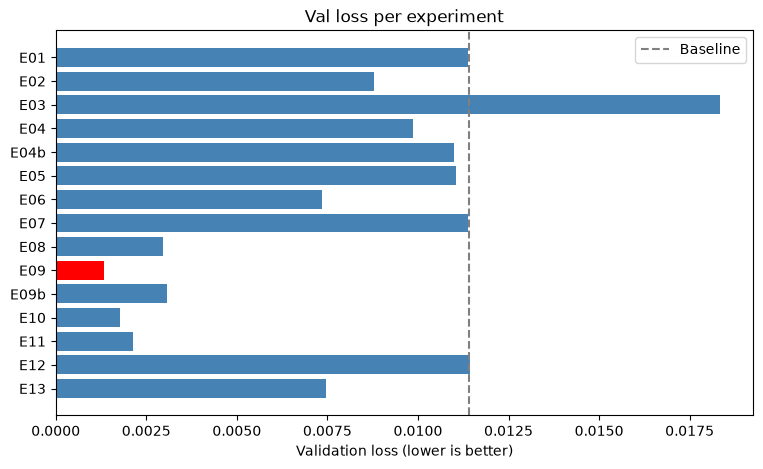

In [16]:
# 1) Val loss of every experiment (chosen model in red)
colors = ["red" if exp_id == best["ID"] else "steelblue" for exp_id in results_df["ID"]]

plt.figure(figsize=(9, 5))
plt.barh(results_df["ID"], results_df["Val Loss"], color=colors)
plt.axvline(baseline_loss, color="gray", linestyle="--", label="Baseline")
plt.xlabel("Validation loss (lower is better)")
plt.title("Val loss per experiment")
plt.gca().invert_yaxis()
plt.legend()
plt.savefig(OUT / "plots/tuning_val_loss.png", dpi=150, bbox_inches="tight")
plt.show()

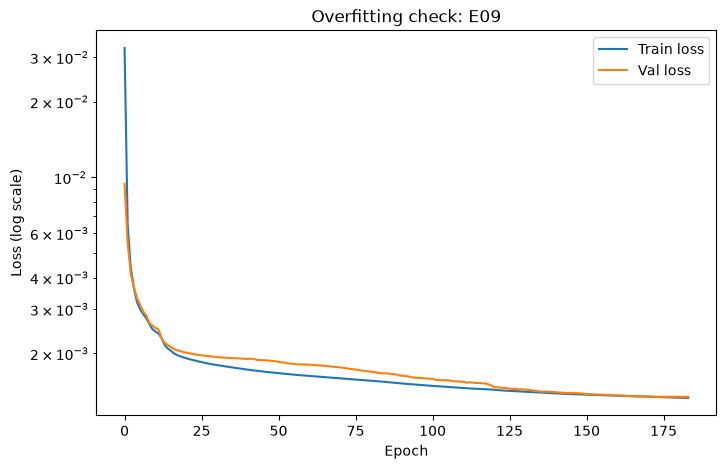

Train loss: 0.001365
Val loss:   0.001344
Gap: -1.5%
No overfitting: train and val loss are close


In [17]:
# 2) Overfitting check: train loss vs val loss of the best model
h = histories[best["ID"]]

plt.figure(figsize=(8, 5))
plt.plot(h["loss"], label="Train loss")
plt.plot(h["val_loss"], label="Val loss")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.title(f"Overfitting check: {best['ID']}")
plt.legend()
plt.savefig(OUT / "plots/overfitting_check.png", dpi=150, bbox_inches="tight")
plt.show()

# Loss on the full train set vs val set (final weights)
train_loss = float(np.mean((x_train - best_model.predict(x_train, batch_size=4096, verbose=0)) ** 2))
val_loss_best = val_loss(best_model)
gap = (val_loss_best - train_loss) / train_loss * 100

print("Train loss:", round(train_loss, 6))
print("Val loss:  ", round(val_loss_best, 6))
print(f"Gap: {gap:.1f}%")

if gap < 5:
    print("No overfitting: train and val loss are close")
else:
    print("Possible overfitting: val loss is much higher than train loss")

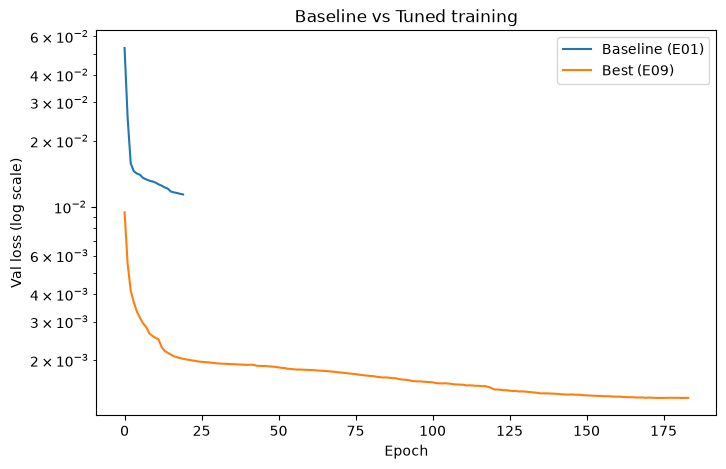

In [18]:
# 3) Val loss curve: baseline (E01) vs best model
plt.figure(figsize=(8, 5))
plt.plot(histories["E01"]["val_loss"], label="Baseline (E01)")
plt.plot(histories[best["ID"]]["val_loss"], label=f"Best ({best['ID']})")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Val loss (log scale)")
plt.title("Baseline vs Tuned training")
plt.legend()
plt.savefig(OUT / "plots/baseline_vs_tuned_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## Reflection Questions
*(Answer after running.)*
1. Which hyperparameter had the biggest impact on val loss?
*
2. Did Early Stopping help? After how many epochs did it stop?
*
3. Did bigger or deeper layers always improve the result?
*
4. Did L2 or Dropout help? Why / why not?
*
5. Which model would you choose, and why?
*